# Part 1 — Reproducing the paper (gentrification early warning, California)

**Task:** from 2010–2011 tract data, predict whether a tract changed by 2016 — two yes/no targets:
- `y_cost`: median monthly housing cost went up (2012 → 2016)
- `y_income`: share of high-income households went up (2012 → 2016)

**Models (paper's settings):** Random Forest, XGBoost, L1 Logistic Regression, a majority-vote ensemble of the three, and a "always predict the majority class" baseline.
**Metrics:** accuracy, precision, recall on the held-out test set.

## 1. Data and split

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

df = pd.read_csv("gentrification_dataset.csv", index_col="GEO_ID")
LABELS = ["y_cost", "y_income"]

# Predictors = 188 tract features + 4 spatial features. Everything built from 2012-2016 data is excluded (it would leak the answer).
NOT_FEATURES = ["split", "y_cost", "y_income", "cost_change_2012_2016", "cost_change_2012_2016_cpi_adjusted",
                "y_cost_cpi_adjusted", "income_affluence_change_2012_2016", "income_change_scaled_0_100"]
FEATURES = [c for c in df.columns if c not in NOT_FEATURES]

# The split was made once when building the dataset (random 90/5/5 over tracts, seed 42)
tr, va, te = (df[df.split == s] for s in ("train", "val", "test"))
print(len(FEATURES), "features | train/val/test =", len(tr), len(va), len(te))

192 features | train/val/test = 7137 397 397


## 2. Models
Each model is a pipeline: fill missing values with the training median → (scale, for logistic regression) → model. Fitting a pipeline learns the medians from training rows only.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

SEED = 42
def make_models():
    return {
        "Random Forest":    make_pipeline(SimpleImputer(strategy="median"),
                                          RandomForestClassifier(n_estimators=125, max_features=18, random_state=SEED)),
        "XGBoost":          make_pipeline(SimpleImputer(strategy="median"),
                                          XGBClassifier(learning_rate=0.25, max_depth=4, reg_lambda=25, random_state=SEED)),
        "L1 Logistic Reg.": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                          LogisticRegression(penalty="l1", C=0.005, solver="liblinear")),
    }

## 3. Train and evaluate
Training is the `.fit(...)` line, on training rows only. The test rows are only ever passed to `.predict(...)`.

In [3]:
def metrics(y, p):
    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p), recall=recall_score(y, p))

preds, models, rows = {}, {}, []
for label in LABELS:
    models[label], preds[label] = make_models(), {}
    for name, model in models[label].items():
        model.fit(tr[FEATURES], tr[label])                       # <-- training happens here
        preds[label][name] = model.predict(te[FEATURES])
    votes = sum(preds[label].values())                           # how many of the 3 models say "1"
    preds[label]["Ensemble (majority vote)"] = (votes >= 2).astype(int)
    preds[label]["Majority-class baseline"] = np.full(len(te), int(tr[label].mean() >= 0.5))
    for name, p in preds[label].items():
        rows.append(dict(response=label, model=name, **metrics(te[label], p)))

results = pd.DataFrame(rows)
results.to_csv("part1_results.csv", index=False)
order = ["Majority-class baseline", "L1 Logistic Reg.", "Random Forest", "XGBoost", "Ensemble (majority vote)"]
results.pivot_table(index="model", columns="response", values=["accuracy", "precision", "recall"]).loc[order].round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1407: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


accuracy          precision          recall         
response                   y_cost y_income    y_cost y_income y_cost y_income
model                                                                        
Majority-class baseline     0.494    0.660     0.494    0.660  1.000    1.000
L1 Logistic Reg.            0.678    0.660     0.652    0.660  0.745    1.000
Random Forest               0.678    0.693     0.642    0.703  0.786    0.924
XGBoost                     0.698    0.673     0.671    0.714  0.760    0.840
Ensemble (majority vote)    0.685    0.700     0.658    0.700  0.755    0.954

Note: with only 397 test tracts, one accuracy number is uncertain by about ±4.6 points (95% interval), so differences of a few points between models are not meaningful.

## 4. Confusion matrices (test set)
Rows = true class, columns = predicted class (0 / 1).

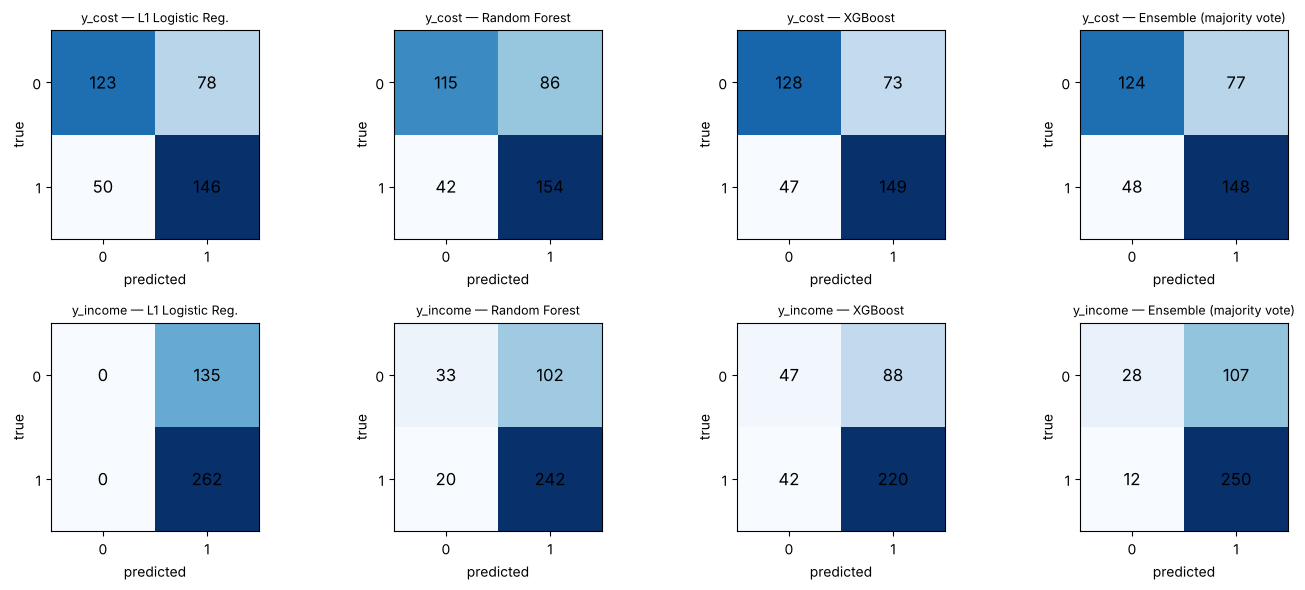

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i, label in enumerate(LABELS):
    for j, name in enumerate(order[1:]):
        cm = confusion_matrix(te[label], preds[label][name], labels=[0, 1])
        ax = axes[i, j]; ax.imshow(cm, cmap="Blues")
        for (a, b), v in np.ndenumerate(cm): ax.text(b, a, v, ha="center", va="center", fontsize=12)
        ax.set_title(f"{label} — {name}", fontsize=9); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

## 5. Which features does XGBoost rely on?
The paper reports the spatial features (`sp_*`) as most important. Here is what our data shows.

y_cost | rank of spatial features (of 192): {'sp_lag_cost': 26, 'sp_lag_income': 67, 'sp_moran_cost': 62, 'sp_moran_income': 80}
y_income | rank of spatial features (of 192): {'sp_lag_cost': 59, 'sp_lag_income': 24, 'sp_moran_cost': 41, 'sp_moran_income': 74}


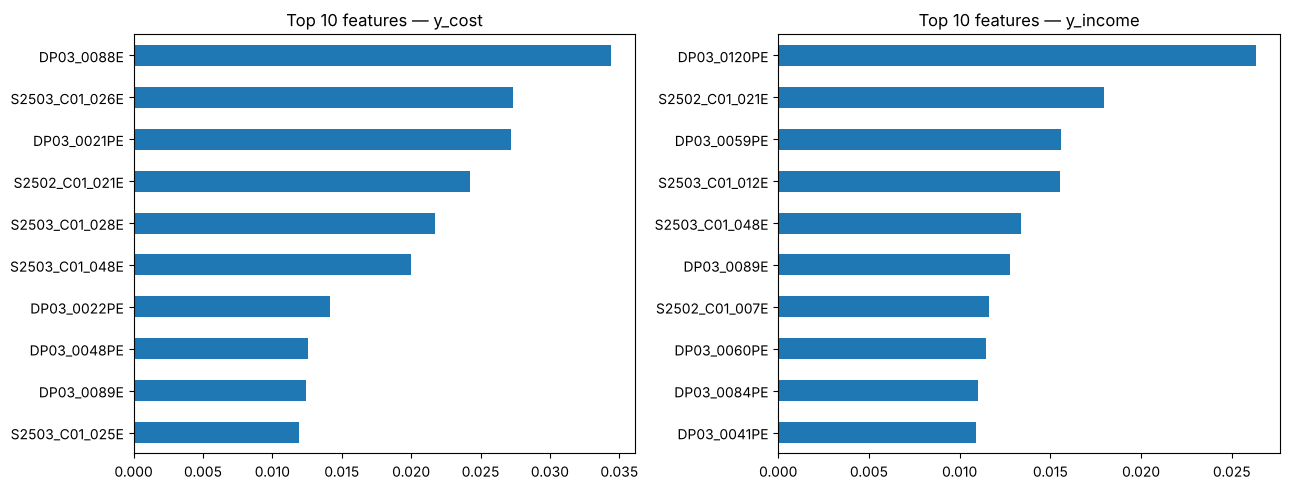

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, label in zip(axes, LABELS):
    imp = pd.Series(models[label]["XGBoost"][-1].feature_importances_, index=FEATURES).sort_values(ascending=False)
    imp.head(10)[::-1].plot.barh(ax=ax, title=f"Top 10 features — {label}")
    print(label, "| rank of spatial features (of 192):", {c: int(imp.rank(ascending=False)[c]) for c in FEATURES if c.startswith("sp_")})
plt.tight_layout(); plt.show()